In [1]:
import sys
import os
import json
from typing import NamedTuple
import math
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_worm import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
ll = 'll00'
data_variant = 'gcamp'
model_variant = 'ns'
organism = 'worm-2025-fieseler'

In [4]:
file_id = 19
neuron_labels = ['VB02', 'SMDDR', 'DB01', 'AVAR']

In [5]:
manual = False

if manual:
	with open('../../hyperparams_manual.json', 'r') as f:
		reg_lambdas = json.load(f)
else:
	with open('../../hyperparams.json', 'r') as f:
		reg_lambdas = json.load(f)['geometric'][ll]

bom_folder = (f'{data_variant}_bom_{model_variant}_'
			  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['bom'][param]:.2E}' for param in reg_lambdas[model_variant]['bom'].keys()]))
hgm_folder = (f'{data_variant}_hgm_{model_variant}_'
			  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['hgm'][param]:.2E}' for param in reg_lambdas[model_variant]['hgm'].keys()]))

In [6]:
path = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')

# read
(filename,
 traces,
 continuous_behaviors,
 discrete_states, eigenworms,
 kymograph) = read_utils.get_data(path, file_id)

# clear nan values
mask = eigenworms.notna().all(axis=1)

traces = traces[mask]
continuous_behaviors = continuous_behaviors[mask]
eigenworms = eigenworms[mask]
discrete_states = discrete_states[mask]
kymograph = kymograph[mask]

# naive ID unknown neurons
traces.columns = pd.Index([
	f'{file_id:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in
	enumerate(zip(traces.columns, traces.columns == ''))
])

# preprocess
pass

In [7]:
_, bom_man, bom_rec, bom_res, bom_pres, _, _ = train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', bom_folder), filename)
_, hgm_man, hgm_rec, hgm_res, hgm_pres, _, _ = train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', hgm_folder), filename)

In [15]:
# # hgm_man = [man[man.var().sort_values(ascending=False).index] for man in hgm_man]
# print([man.var() for man in hgm_man])

[M0    72260.968750
M1    59895.164062
dtype: float32, M0    66278.789062
M1    63145.585938
dtype: float32, M0    69460.640625
M1    74317.070312
dtype: float32, M0    60760.152344
M1    71506.710938
dtype: float32, M0    64892.917969
M1    73422.875000
dtype: float32]


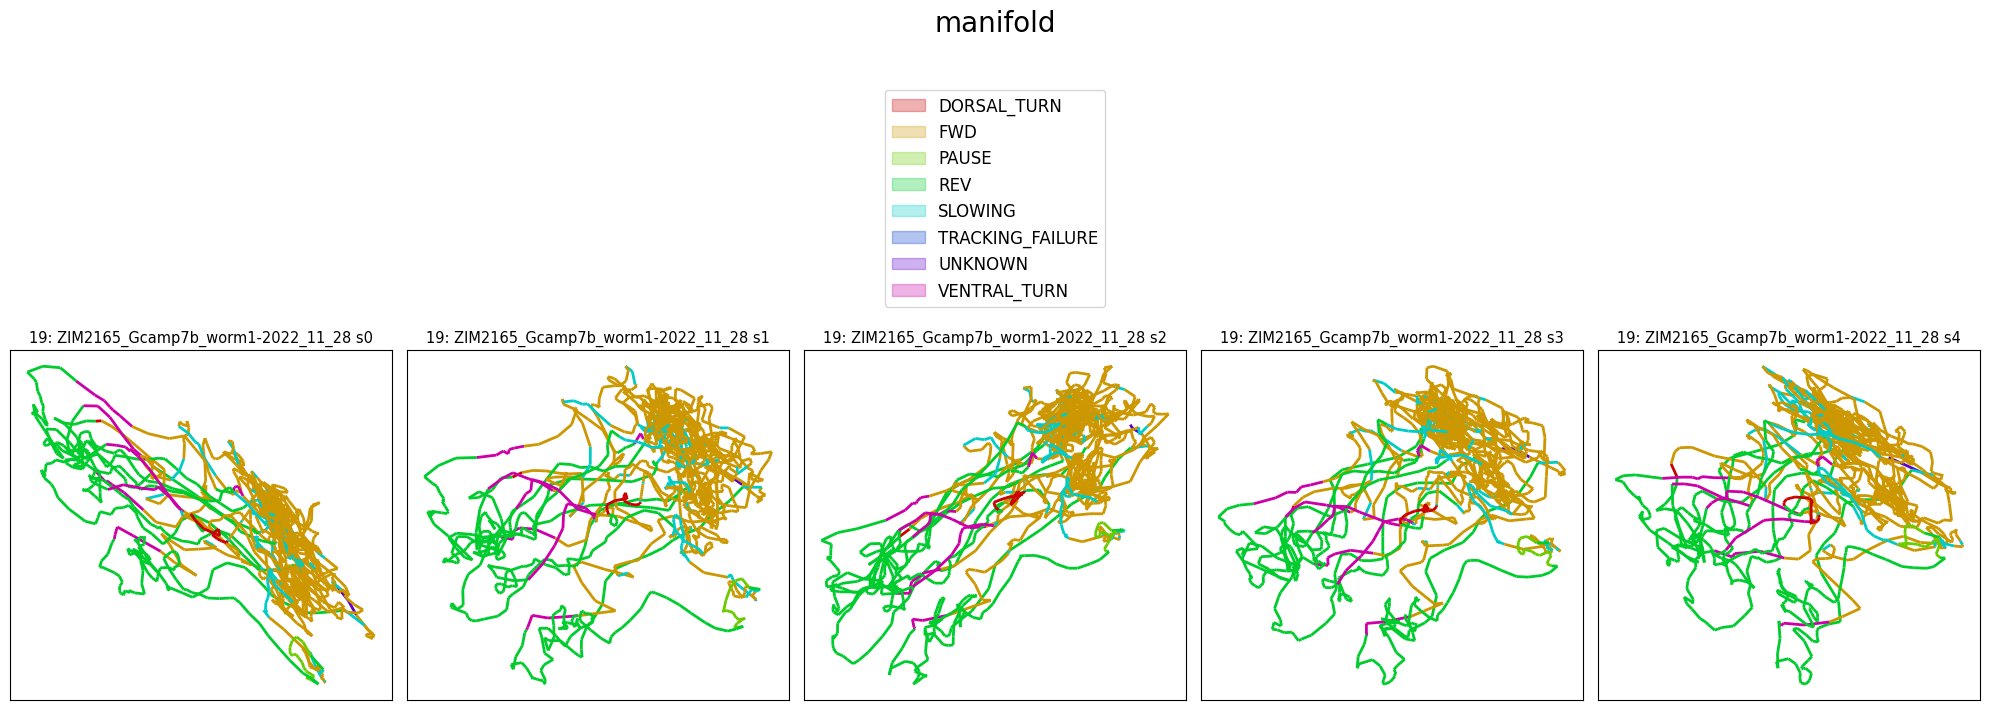

In [8]:
splits = 5
plot_utils.plot_manifolds([f'{str(file_id)}: {filename} s{s}' for s in range(splits)],
						  [hgm_man[s] for s in range(splits)],
						  [discrete_states for s in range(splits)],
						  None, None,
						  title='manifold', plots_per_row=splits, top_space=3.5,
						  save_path=None)

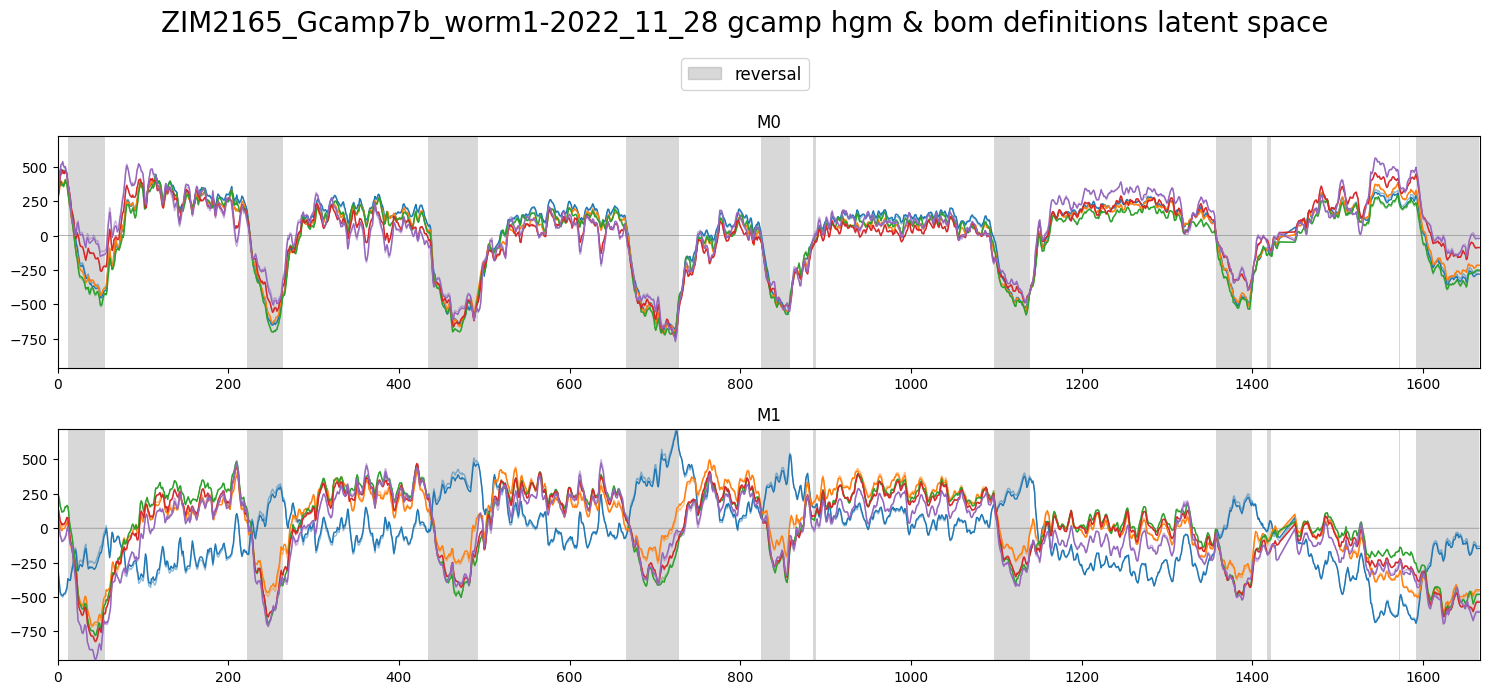

In [14]:
splits = 5
plot_utils.plot_traces_splits(
	[hgm_man[i] for i in range(splits)],
	[bom_man[i] for i in range(splits)],
	None,
	discrete_states[['REV']], label='reversal',
	title=f'{filename} gcamp hgm & bom modes', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_MOD'

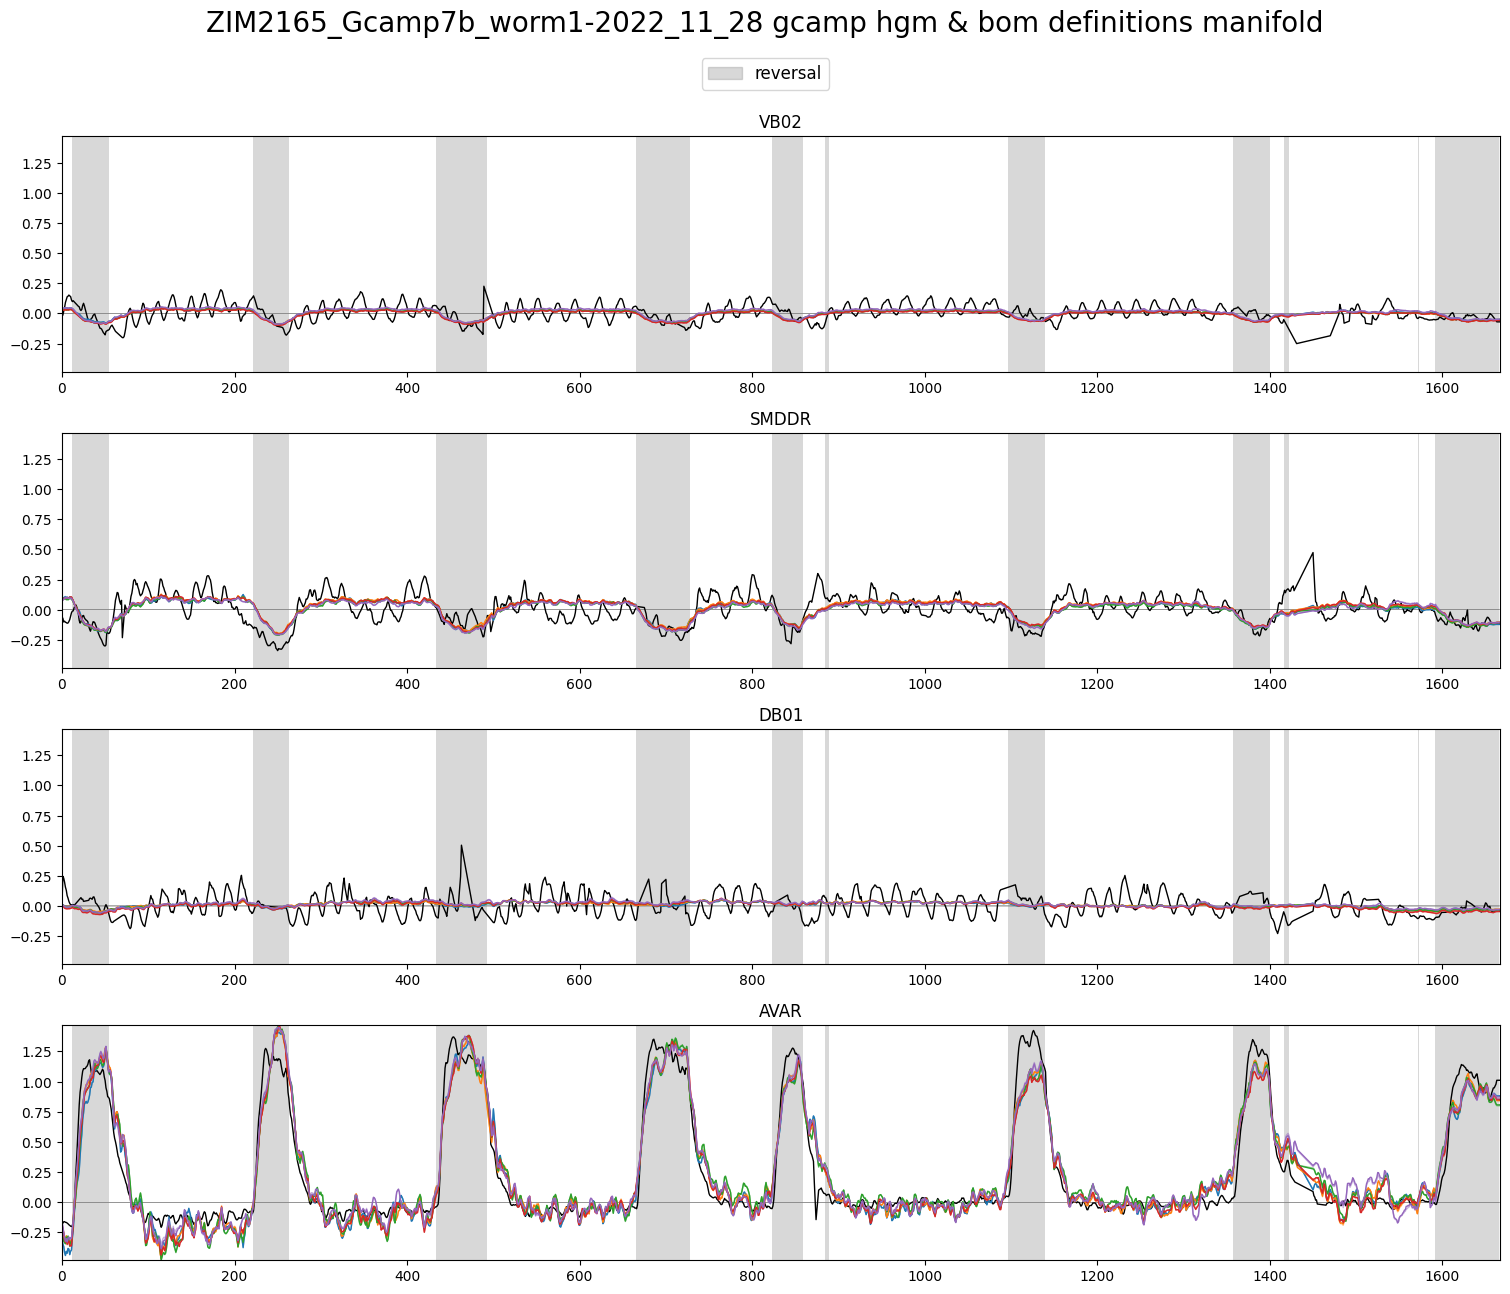

In [9]:
splits = 5
plot_utils.plot_traces_splits(
	[hgm_rec[i][neuron_labels] for i in range(splits)],
	[bom_rec[i][neuron_labels] for i in range(splits)],
	traces[neuron_labels],
	discrete_states[['REV']], label='reversal',
	title=f'{filename} gcamp hgm & bom definitions manifold', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_MAN'

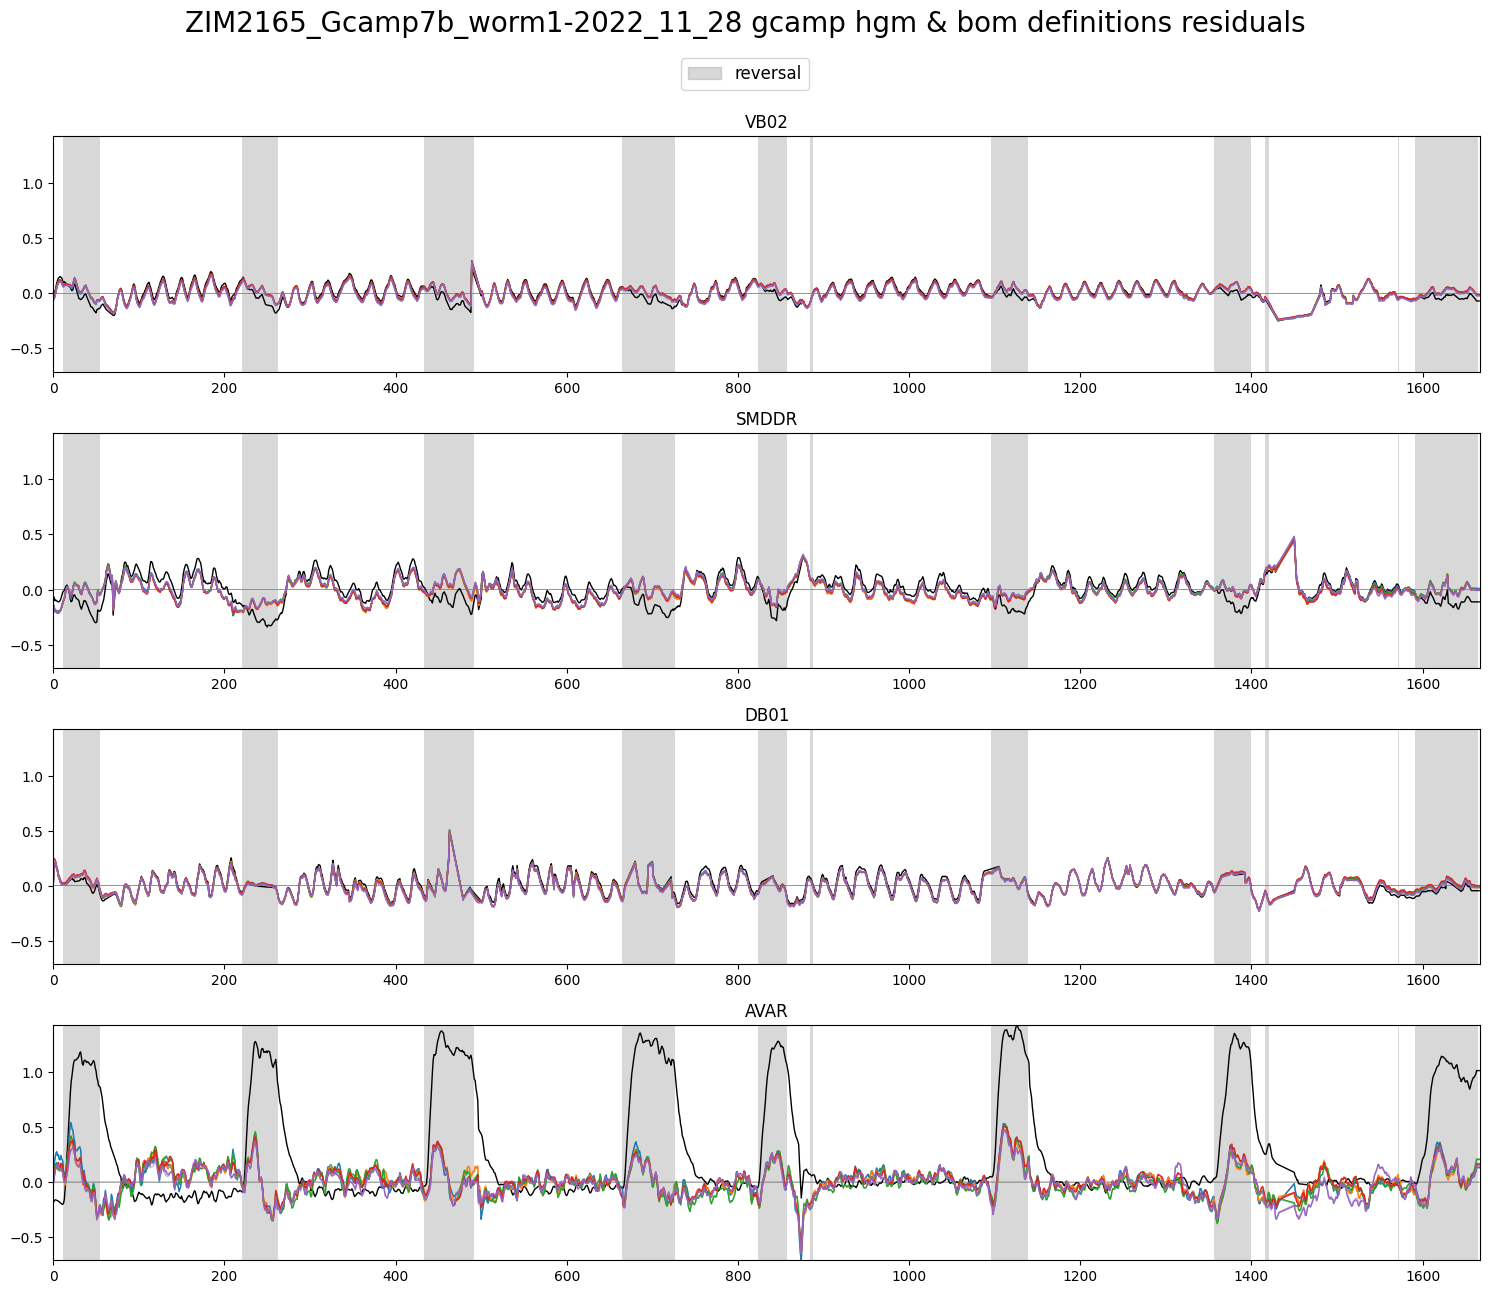

In [10]:
splits = 5
plot_utils.plot_traces_splits(
	[hgm_res[i][neuron_labels] for i in range(splits)],
	[bom_res[i][neuron_labels] for i in range(splits)],
	traces[neuron_labels],
	discrete_states[['REV']], label='reversal',
	title=f'{filename} gcamp hgm & bom definitions residuals', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_RES'

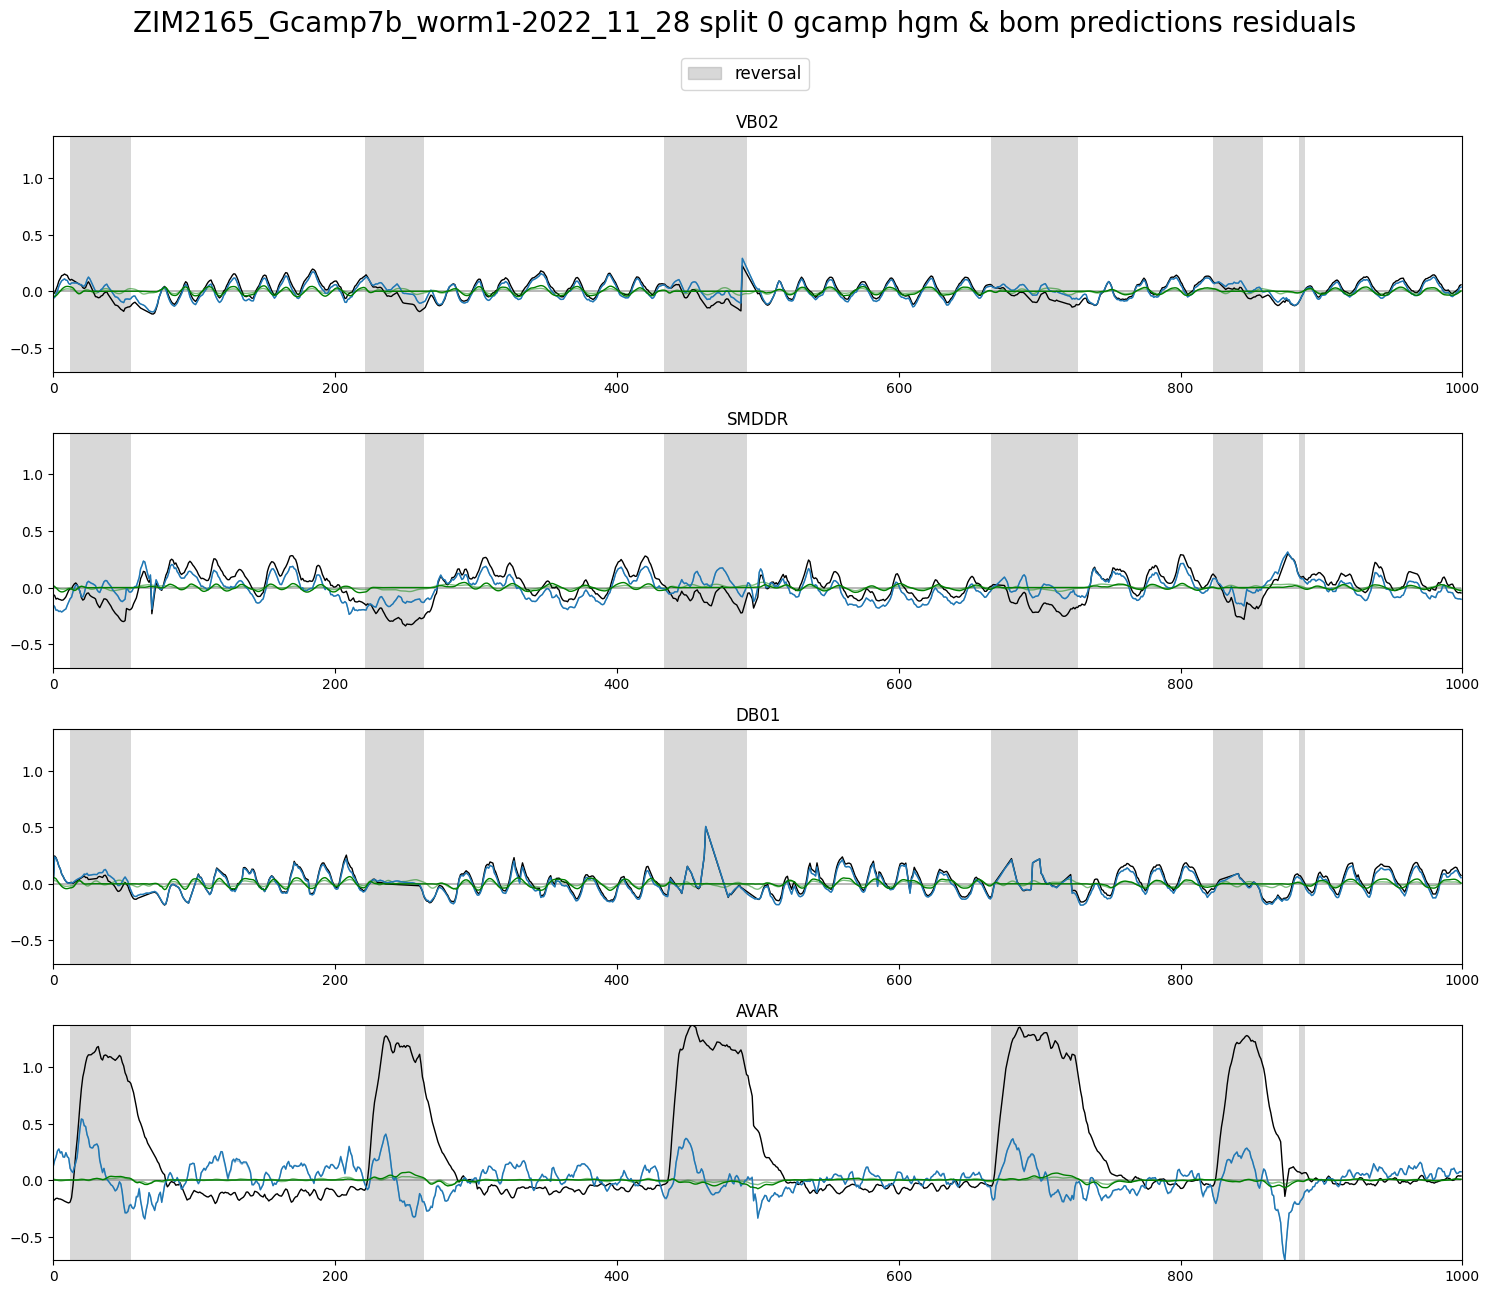

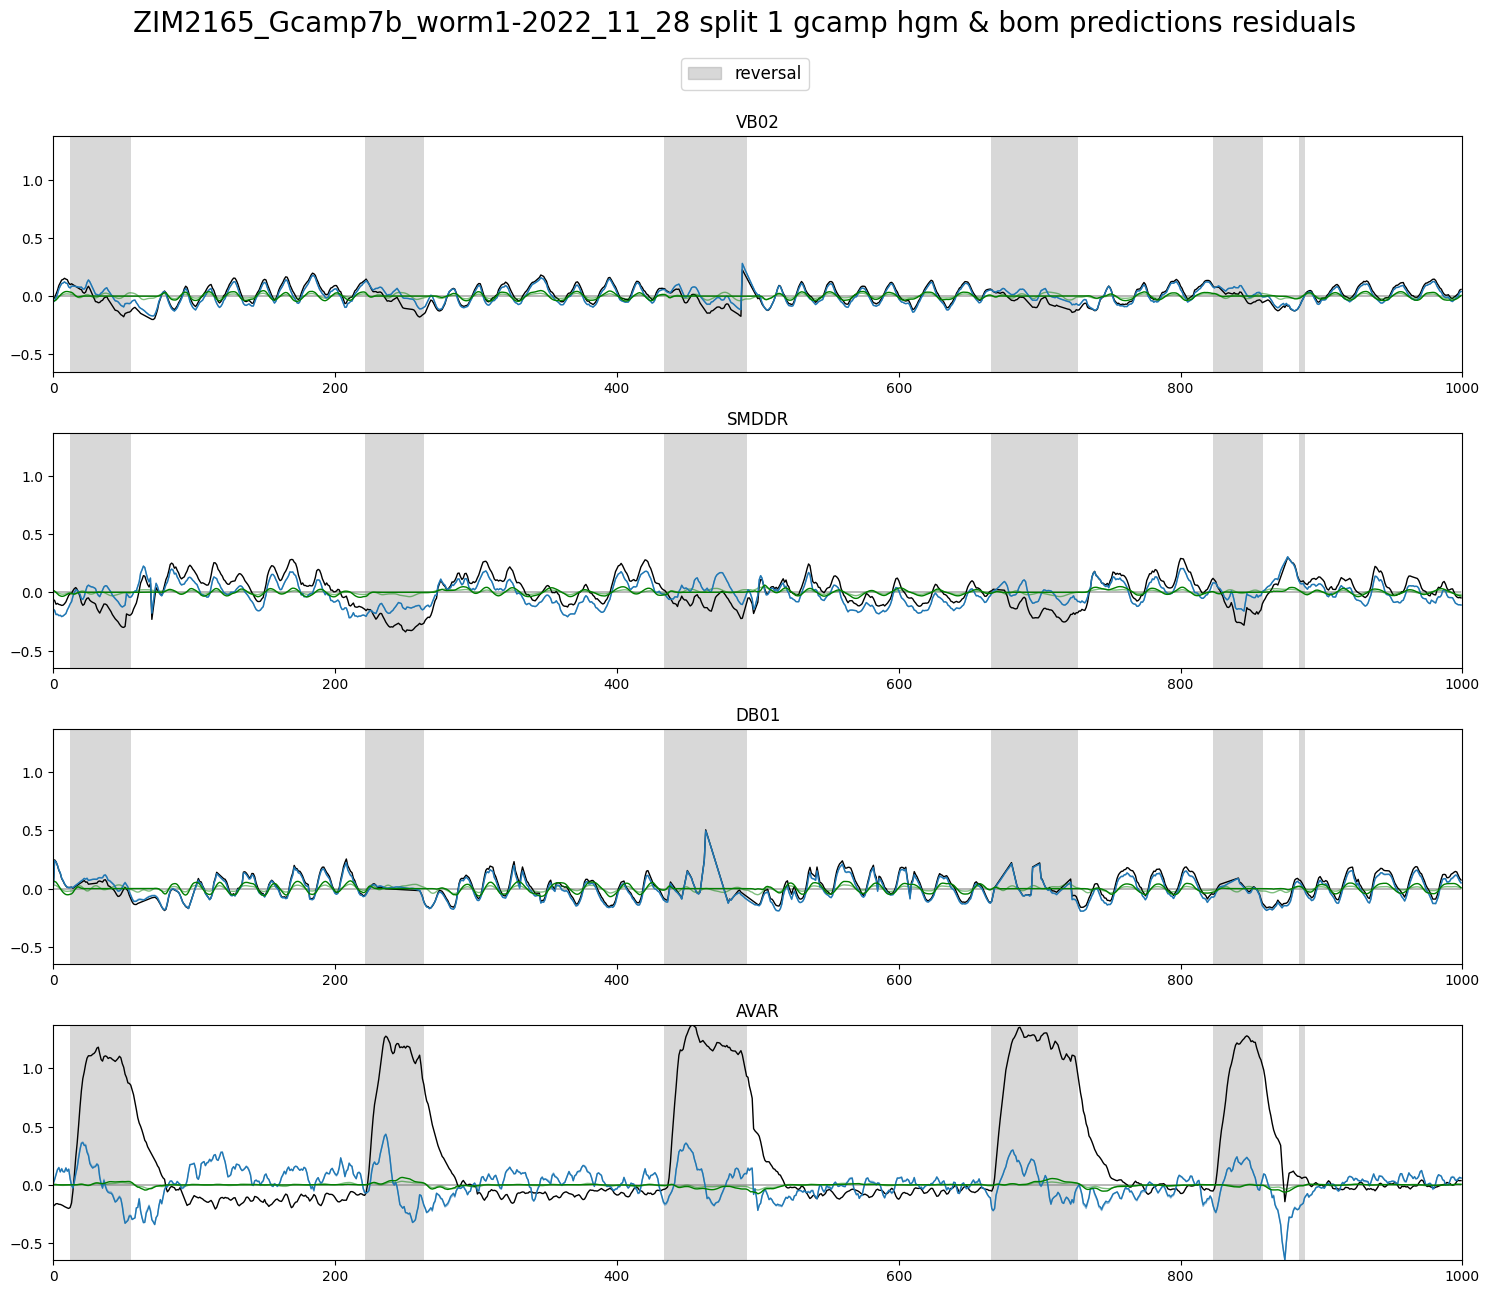

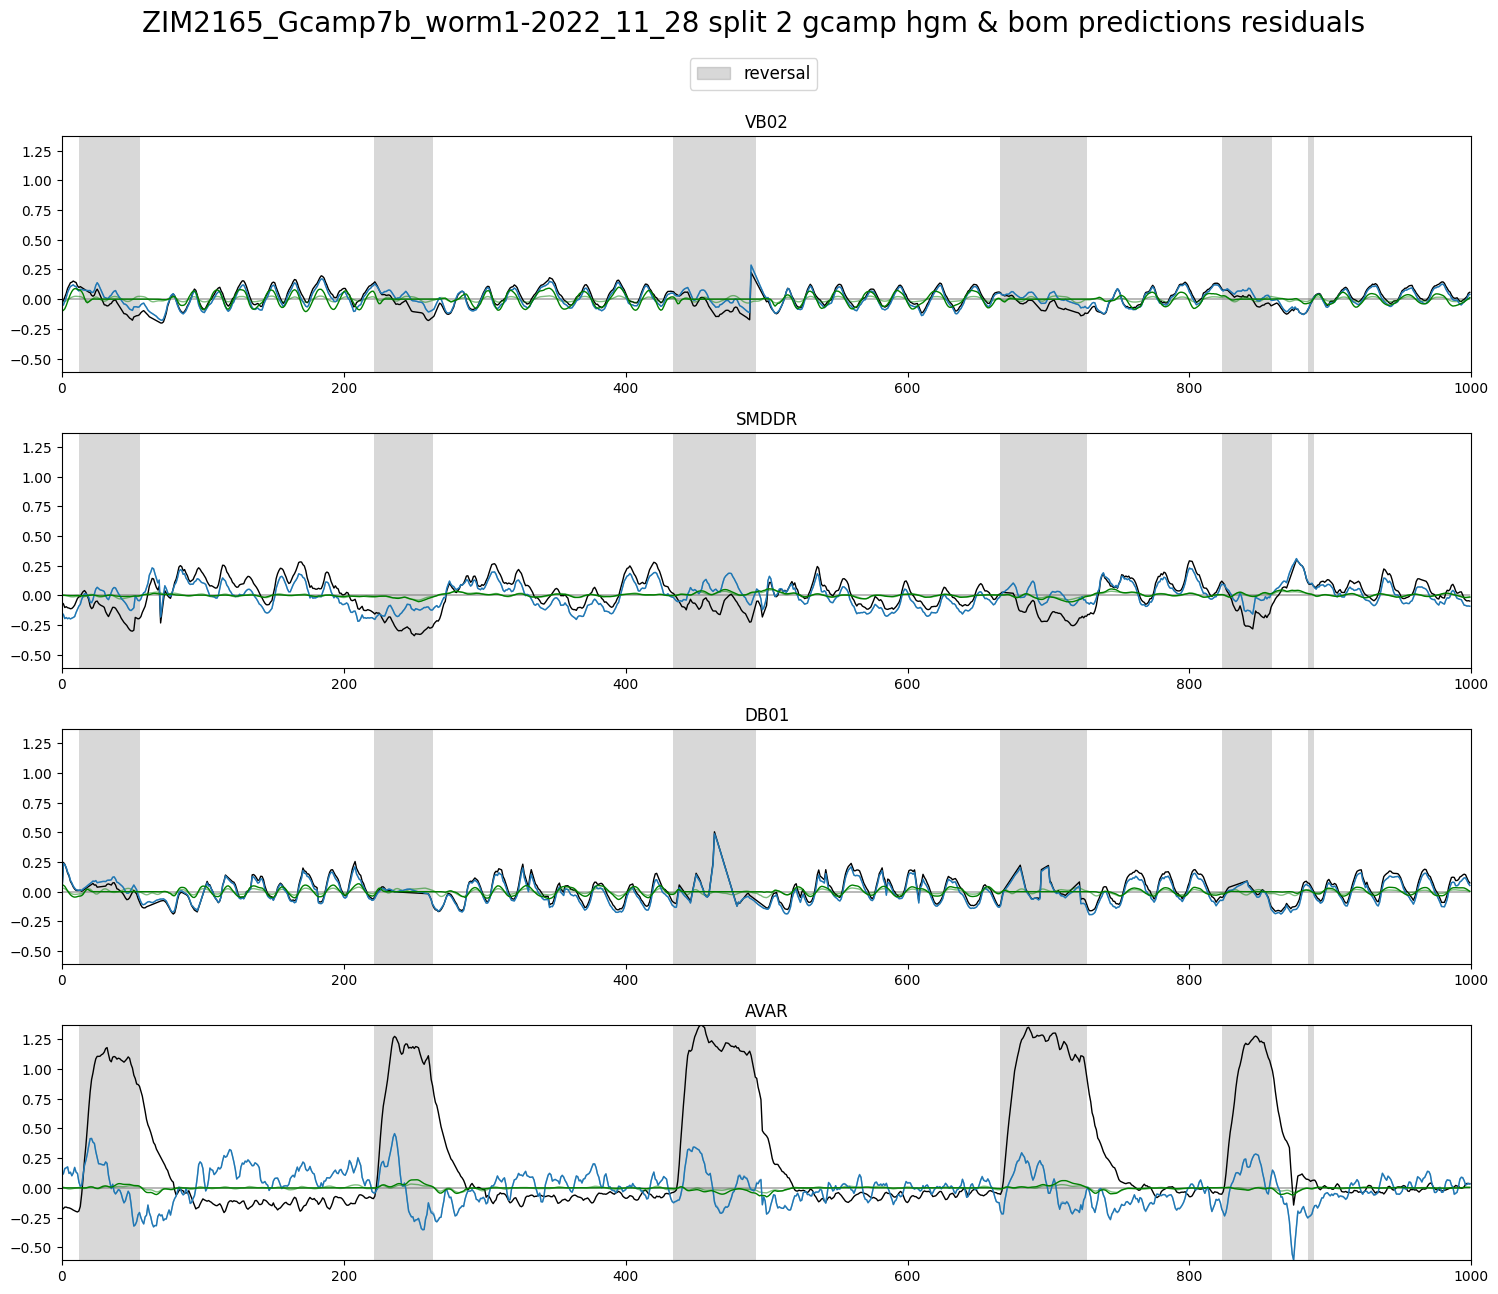

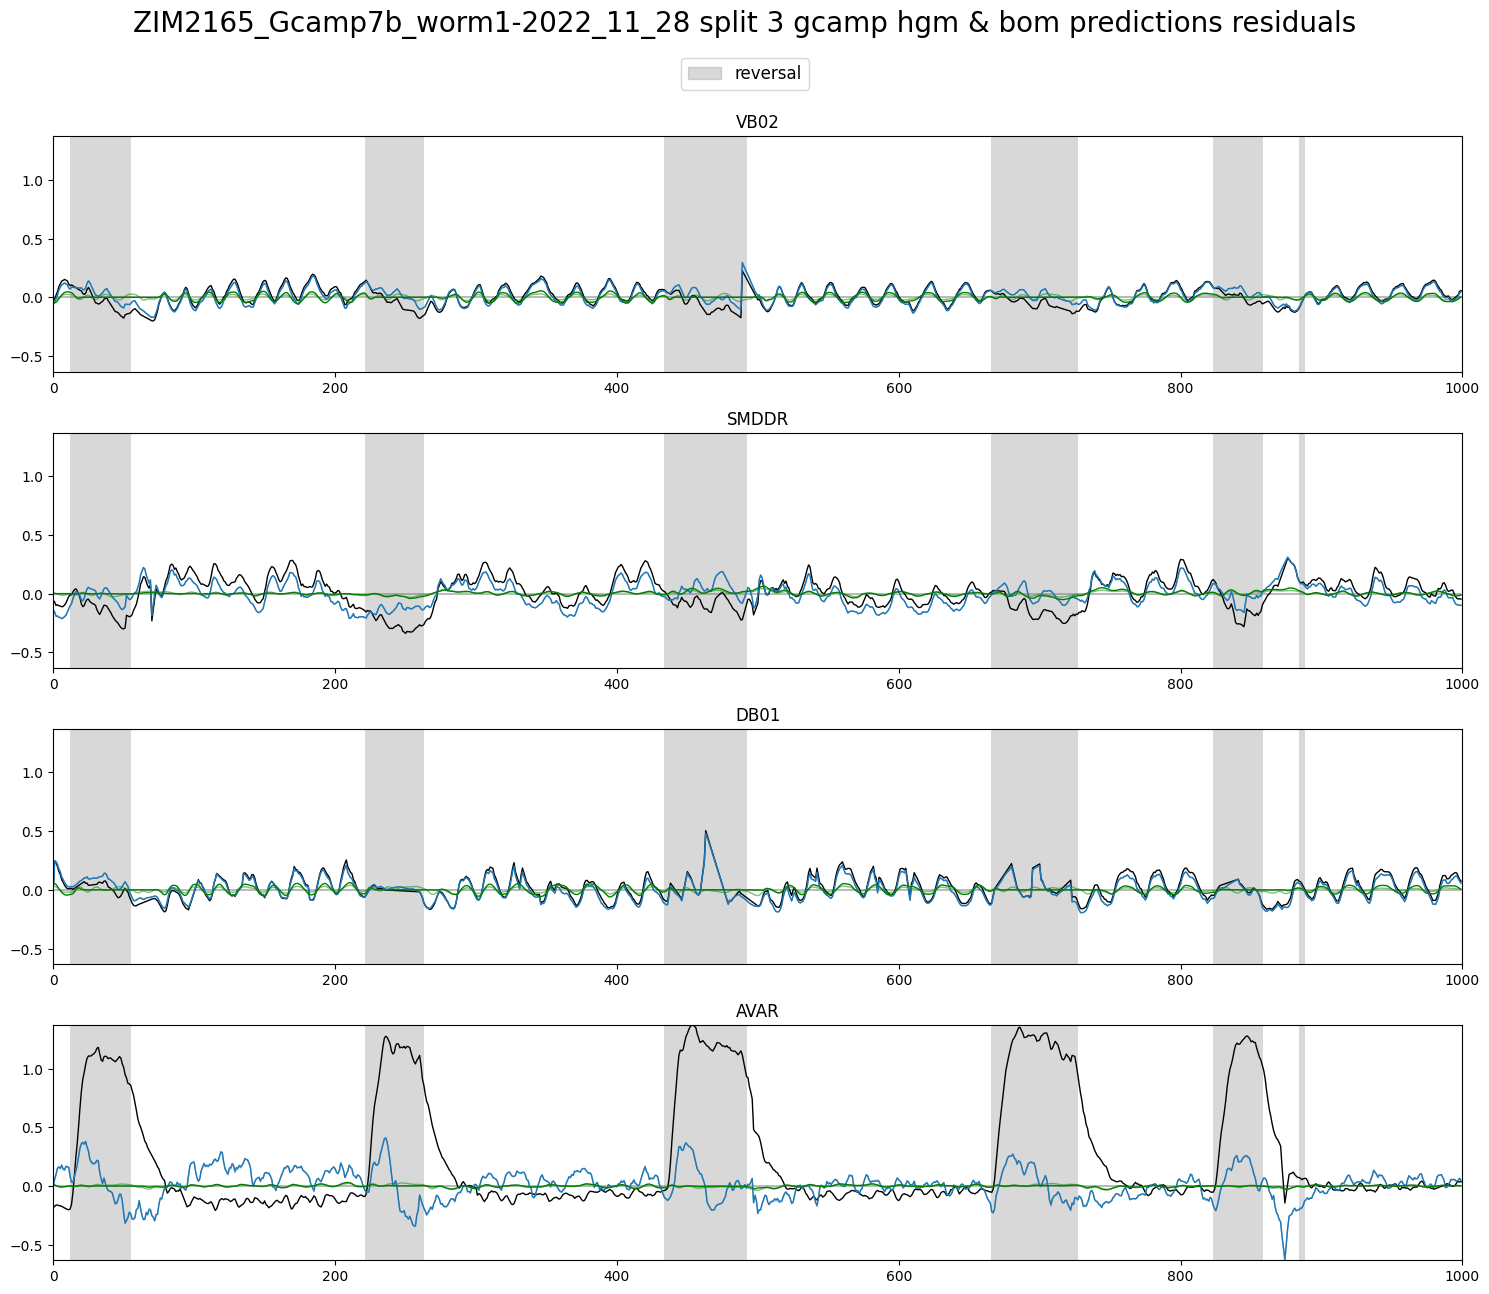

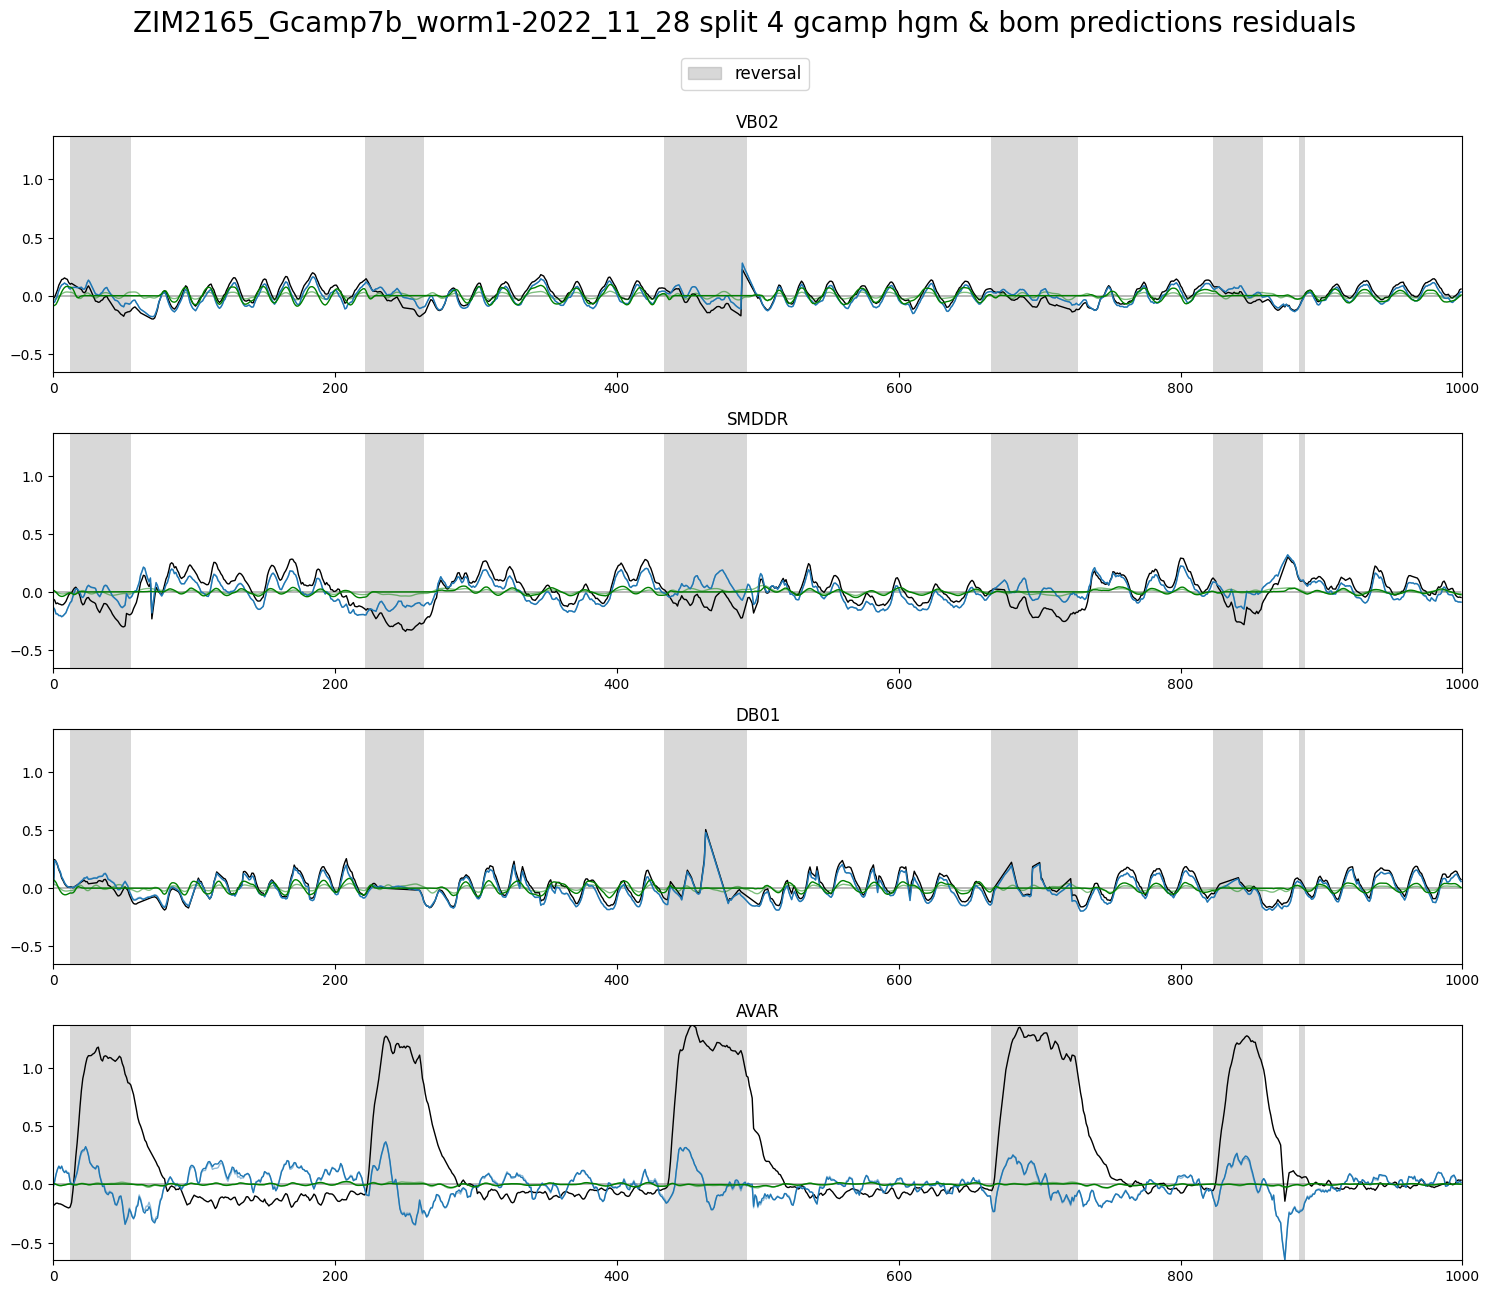

In [11]:
# max_x = traces.values.shape[0]
max_x = 1000

splits = 5
for i in range(splits):
	plot_utils.plot_traces_splits_pairs(
		[hgm_res[i][neuron_labels].iloc[:max_x, :],
		 hgm_pres[i][neuron_labels].iloc[:max_x, :]],
		[bom_res[i][neuron_labels].iloc[:max_x, :],
		 bom_pres[i][neuron_labels].iloc[:max_x, :]],
		traces[neuron_labels].iloc[:max_x, :],
		discrete_states[['REV']].iloc[:max_x, :], label='reversal',
		title=f'{filename} split {i} gcamp hgm & bom predictions residuals', ylimits=None, plots_per_row=1,
		save_path=None)  #../../out/plots/f'GCAMP_PRES_S{i}'

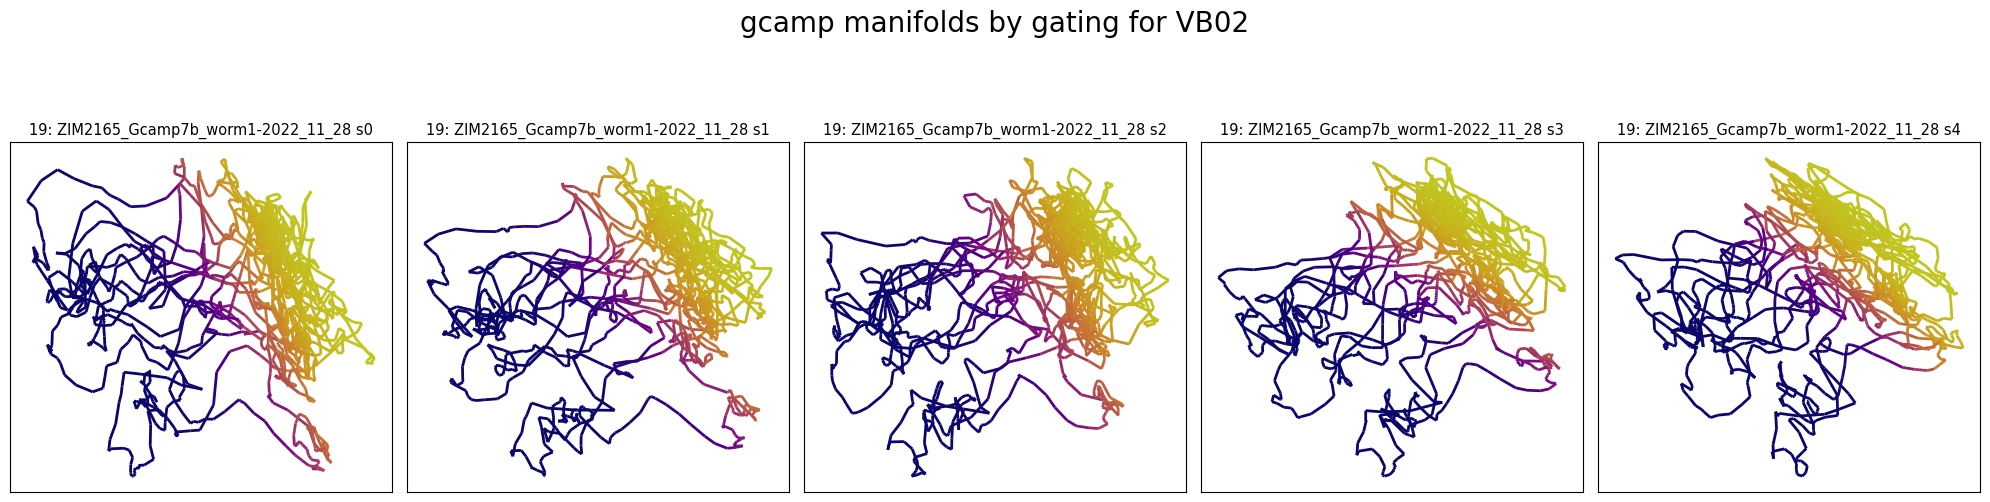

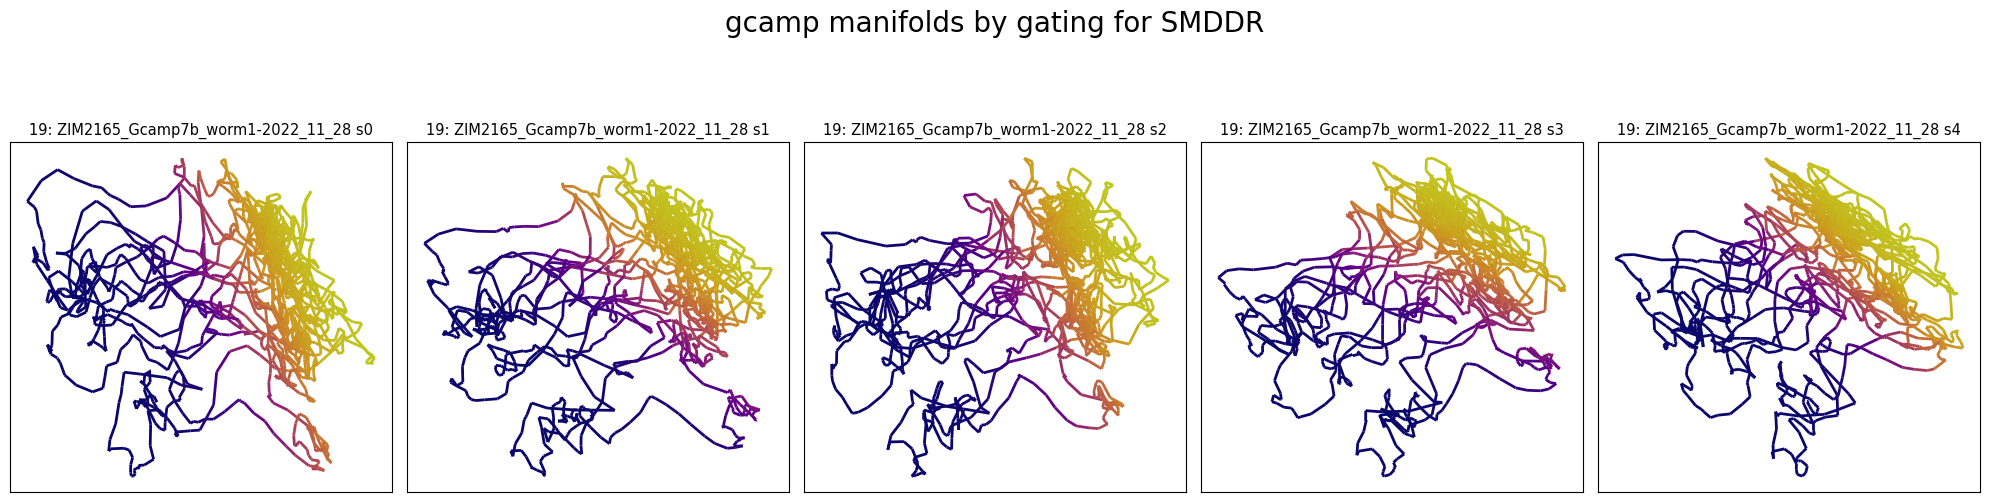

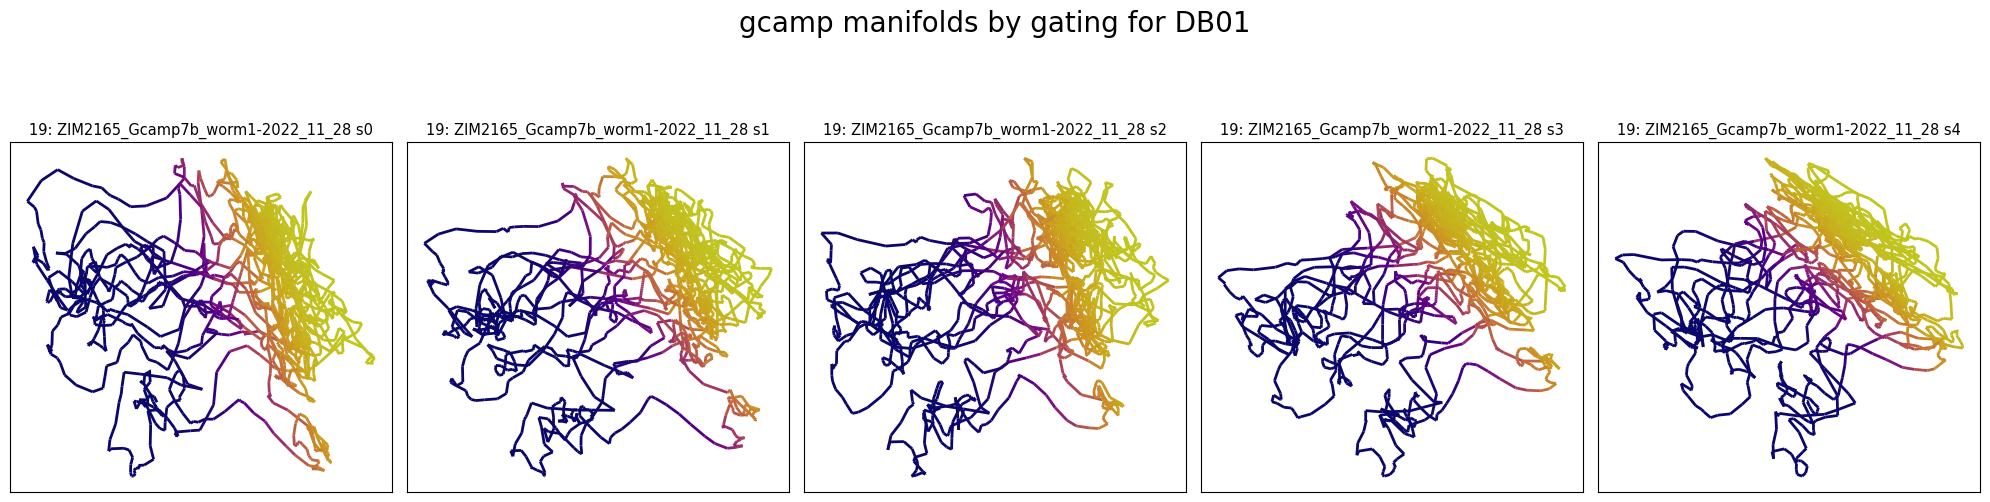

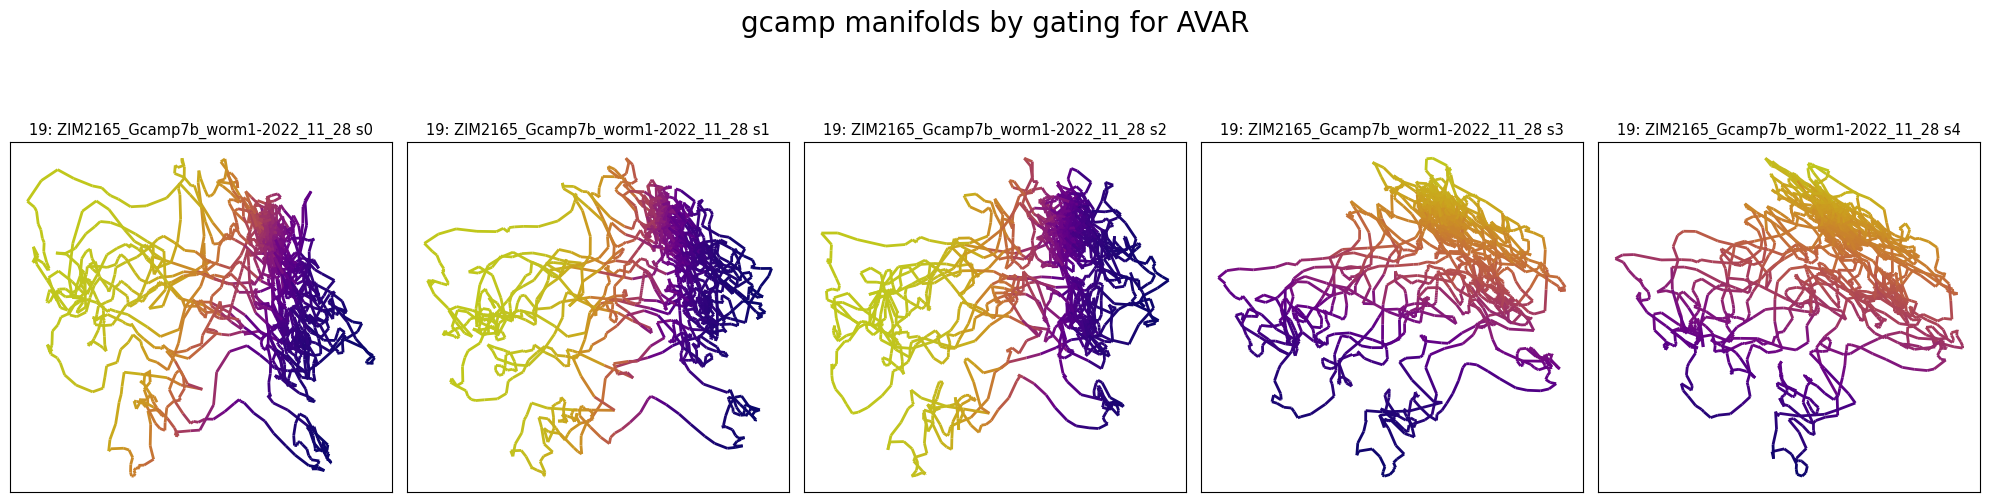

In [24]:
sigmoid = lambda x: 1 / (1 + np.exp(-x))

hgm_folder = f'{data_variant}_hgm_{model_variant}_' + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['hgm'][param]:.2E}' for param in reg_lambdas[model_variant]['hgm'].keys()])
hgm_params = train_utils.load_params(os.path.join(f'{read_utils.get_model_path()}', 'params', hgm_folder), filename)

neurons = neuron_labels
neuron_ids = [traces.columns.get_loc(neuron) for neuron in neurons]

splits = 5

for neuron_id in neuron_ids:
	sigmoid_terms = list()
	for split in range(splits):
		manifold_term = hgm_man[split].values
		manifold_term_zs = (manifold_term - manifold_term.mean(axis=0)) / np.where((N_std := manifold_term.std(axis=0)) == 0.0, 1.0, N_std)

		WM = hgm_params[split]['model']['WM'][:, neuron_id]

		sigmoid_term = sigmoid(manifold_term_zs @ WM)
		sigmoid_terms.append(pd.DataFrame(data=sigmoid_term))

	plot_utils.plot_manifolds_gradient([f'{str(file_id)}: {filename} s{s}' for s in range(splits)],
							  [hgm_man[s] for s in range(splits)],
							  [sigmoid_terms[s] for s in range(splits)],
							  None, None,
							  title=f'gcamp manifolds by gating for {traces.columns[neuron_id]}', plots_per_row=splits, top_space=1,
							  save_path=None)